# 02 · Manifold — principal-curve trajectory (10x malignant manifold)

Jerby-Arnon 2021 synovial sarcoma's malignant manifold is **non-branching**: the
gastrulation / somitogenesis / neural-crest developmental signatures form a single
monotone gradient (Gast & pSom co-vary along the body; Crest is the opposite, terminal
end) rather than a hub radiating to two competing arms. The correct topology is a
**principal curve** (ElPiGraph, non-branching by construction) fit on the *joint*
embedding — **not** a re-embedding (re-embedding an anisotropic compartment fabricates
folds; Kürten §4). The curve is rooted at the gastrulation/somitogenesis-high tip and
pseudotime flows to the neural-crest terminus. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [ ]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
Keep all cells on their *original joint embedding coordinates* — no re-embedding. The
three embryonic signatures are scored against the shared **union** control pool and
graph-smoothed to read geography rather than 10x per-cell dropout.

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('10x malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('global module means: Gast %.3f pSom %.3f Crest %.3f' %
      (adata.obs.Gast.mean(), adata.obs.pSom.mean(), adata.obs.Crest.mean()))

10x malignant manifold: 8322 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.10
Gast: 61/81 genes present
pSom: 73/98 genes present
Crest: 86/104 genes present
global module means: Gast -0.019 pSom 0.187 Crest -0.043


### Scope decision — whole manifold vs a lobe (data-driven)
Test whether the developmental axis is confined to one lobe (Kürten case, where scoping
is justified) or spans the whole manifold (Bischoff/Sun/Lee case, keep everything). Two
facts settle it here: (i) the smoothed signatures co-vary as one axis (Gast↔pSom
positive, both opposite Crest); (ii) cycling is negligible overall (~5%), so the
proliferation split is orthogonal to the developmental axis — excluding any lobe would
truncate the gradient under test.

In [ ]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-compartment smoothed developmental means:')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm','cycling']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict()
print('\nCrest-high decile across compartments:', frac)
print('-> single developmental axis, cycling negligible; keep the whole manifold (no scoping).')
sub = adata

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.76
  Crest_sm vs Gast_sm: r = -0.75
  Crest_sm vs pSom_sm: r = -0.97

per-compartment smoothed developmental means:
                   Gast_sm  pSom_sm  Crest_sm  cycling
compartment                                           
Cycling/Metabolic  -0.0241   0.1714   -0.0282   0.0586
Embryonic           0.0015   0.2633   -0.1185   0.0274

Crest-high decile across compartments: {'Cycling/Metabolic': 1.0, 'Embryonic': 0.0}
-> single developmental axis, cycling negligible; keep the whole manifold (no scoping).


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone. A node self-approach
ratio > 1 (minimum distance between graph-non-adjacent nodes, in units of median edge
length) certifies the curve does not fold back on itself. `epg_mu=100` is strong bending
regularisation, keeping the arc smooth. Fold-freedom is confirmed across `Nodes` 15/20/30.

In [ ]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks
for Nodes in [15, 20, 30]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(sub, Nodes=Nodes, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(sub)
    print(f'curve Nodes={Nodes}: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'committed Nodes=20: {tips} tips, {forks} forks, self-approach {sa:.2f}')
assert forks == 0 and sa > 1, 'topology check failed'

curve Nodes=15: 2 tips, 0 forks | fold self-approach ratio = 2.86 (>1 = fold-free)
curve Nodes=20: 2 tips, 0 forks | fold self-approach ratio = 2.58 (>1 = fold-free)
curve Nodes=30: 2 tips, 0 forks | fold self-approach ratio = 2.20 (>1 = fold-free)
committed Nodes=20: 2 tips, 0 forks, self-approach 2.58


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the
developmental origin. Pseudotime then flows to the neural-crest terminus (the Kürten
rule: root from developmental order, never at Crest or a cycling state).

In [ ]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho on smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0399 pSom=+0.1435 Crest=-0.0095
tip 2: Gast=-0.0020 pSom=+0.2530 Crest=-0.1073
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.731 p=0.0e+00
  pSom_sm: rho=-0.895 p=0.0e+00
  Crest_sm: rho=+0.854 p=0.0e+00
  cyc_score: rho=+0.036 p=1.2e-03


### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates (discrete sign choice, no rotation — an SVD
basis can silently reflect an axis). If the trajectory is not already horizontal we swap
axes so the developmental axis is horizontal, then flip so low pseudotime lands on the
left.

In [ ]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
# choose the axis most aligned with pseudotime as the horizontal (developmental) axis
rx = abs(np.corrcoef(xy[:,0], t)[0,1]); ry = abs(np.corrcoef(xy[:,1], t)[0,1])
xyr = xy.copy() if rx >= ry else np.column_stack([xy[:,1], xy[:,0]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: {"identity" if rx>=ry else "axis-swap"}; corr(x_lin, pseudotime) = {r:+.2f}')

orientation: axis-swap; corr(x_lin, pseudotime) = +0.70


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


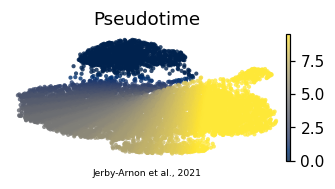

In [ ]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Jerby-Arnon et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
plt.show()
print('saved manifold.h5ad + manifold.pdf')